In [ ]:
# Purpose:
#   Subclassify and annotate dendritic cell populations (DCs) from the integrated PBMC
#   scRNA-seq dataset, resolving cDC1, cDC2, and pDC subtypes.
#
# Summary:
#   - Load Harmony-integrated DC Seurat object
#   - Perform cell-cycle scoring and QC visualization
#   - Remove clusters likely representing doublets or low-quality cells
#   - Recompute neighbors, UMAP, and clustering within cleaned DC population
#   - Assess cluster purity using Azimuth predicted.celltype.l2 labels
#   - Assign dominant DC subtype to high-purity clusters
#   - Define level-3 DC identities (cDC1, cDC2, pDC)
#   - Save finalized annotated DC object

# Header

In [1]:
setwd('/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/github')
source('codes/functions.R')

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.4.0 but the current version is
4.4.2; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t



Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers




In [2]:
options(future.globals.maxSize = 120 * 1024 * 1024 * 1024)

In [3]:
packageVersion("Seurat")

[1] ‘5.3.1.0’

# Load

In [4]:
celltype = 'DC'

In [5]:
obj = qs::qread(glue("data/03_cleandata/itg_{celltype}.qs"))
obj

An object of class Seurat 
28202 features across 8634 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [6]:
exp.mat <- read.table(
    file = "data/geneset/nestorawa_forcellcycle_expressionMatrix.txt",
    header = TRUE, as.is = TRUE, row.names = 1)

s.genes <- cc.genes$s.genes
g2m.genes <- cc.genes$g2m.genes

In [7]:
obj <- CellCycleScoring(obj, 
                        s.features = s.genes, 
                        g2m.features = g2m.genes, 
                        set.ident = TRUE)


Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


# Annotate

In [8]:
colnames(obj@meta.data)

[1] "nFeaturess_RNA"              "nFeaturess_RNA_by_counts"   
 [3] "total_counts"                "total_counts_mt"            
 [5] "pct_counts_mt"               "doublets_pred"              
 [7] "doublets_score"              "nCount_RNA"                 
 [9] "nFeature_RNA"                "percent.mt"                 
[11] "predicted.celltype.l1.score" "predicted.celltype.l1"      
[13] "predicted.celltype.l2.score" "predicted.celltype.l2"      
[15] "predicted.celltype.l3.score" "predicted.celltype.l3"      
[17] "mapping.score"               "RNA_snn_res.0.8"            
[19] "seurat_clusters"             "dataset_name"               
[21] "RNA_snn_res.0.1"             "S.Score"                    
[23] "G2M.Score"                   "Phase"                      
[25] "old.ident"

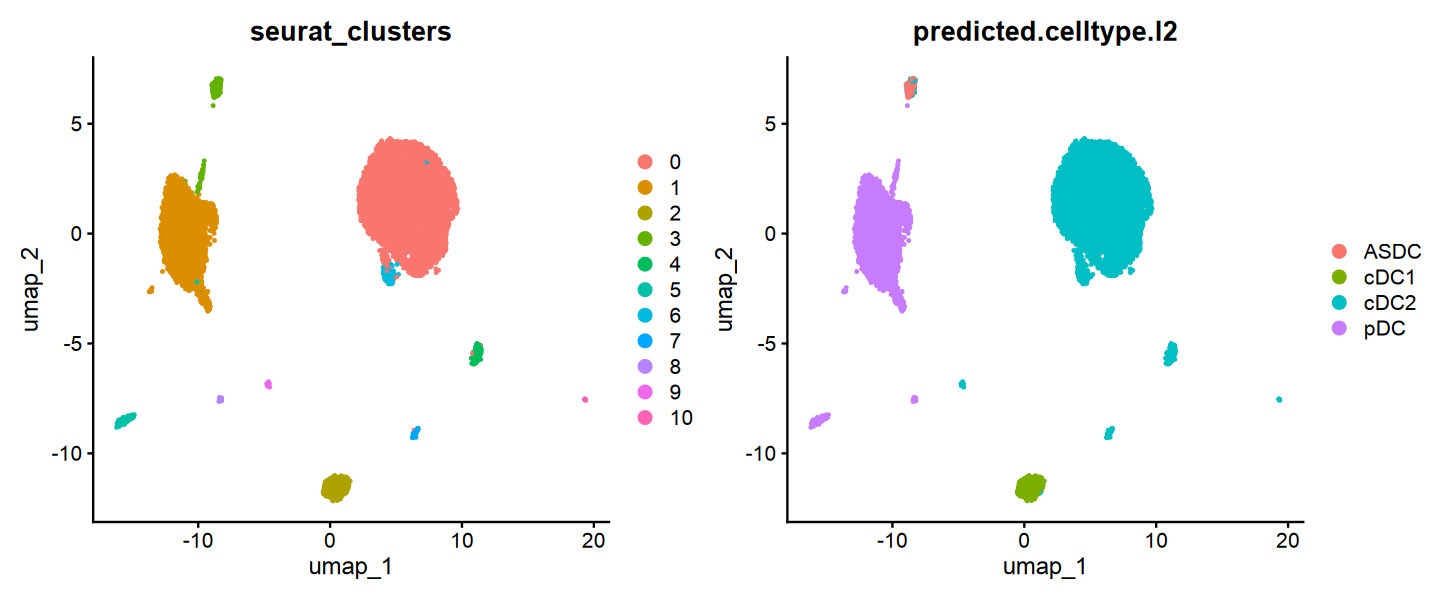

In [9]:
options(repr.plot.width=12, repr.plot.height=5)

DimPlot(obj, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

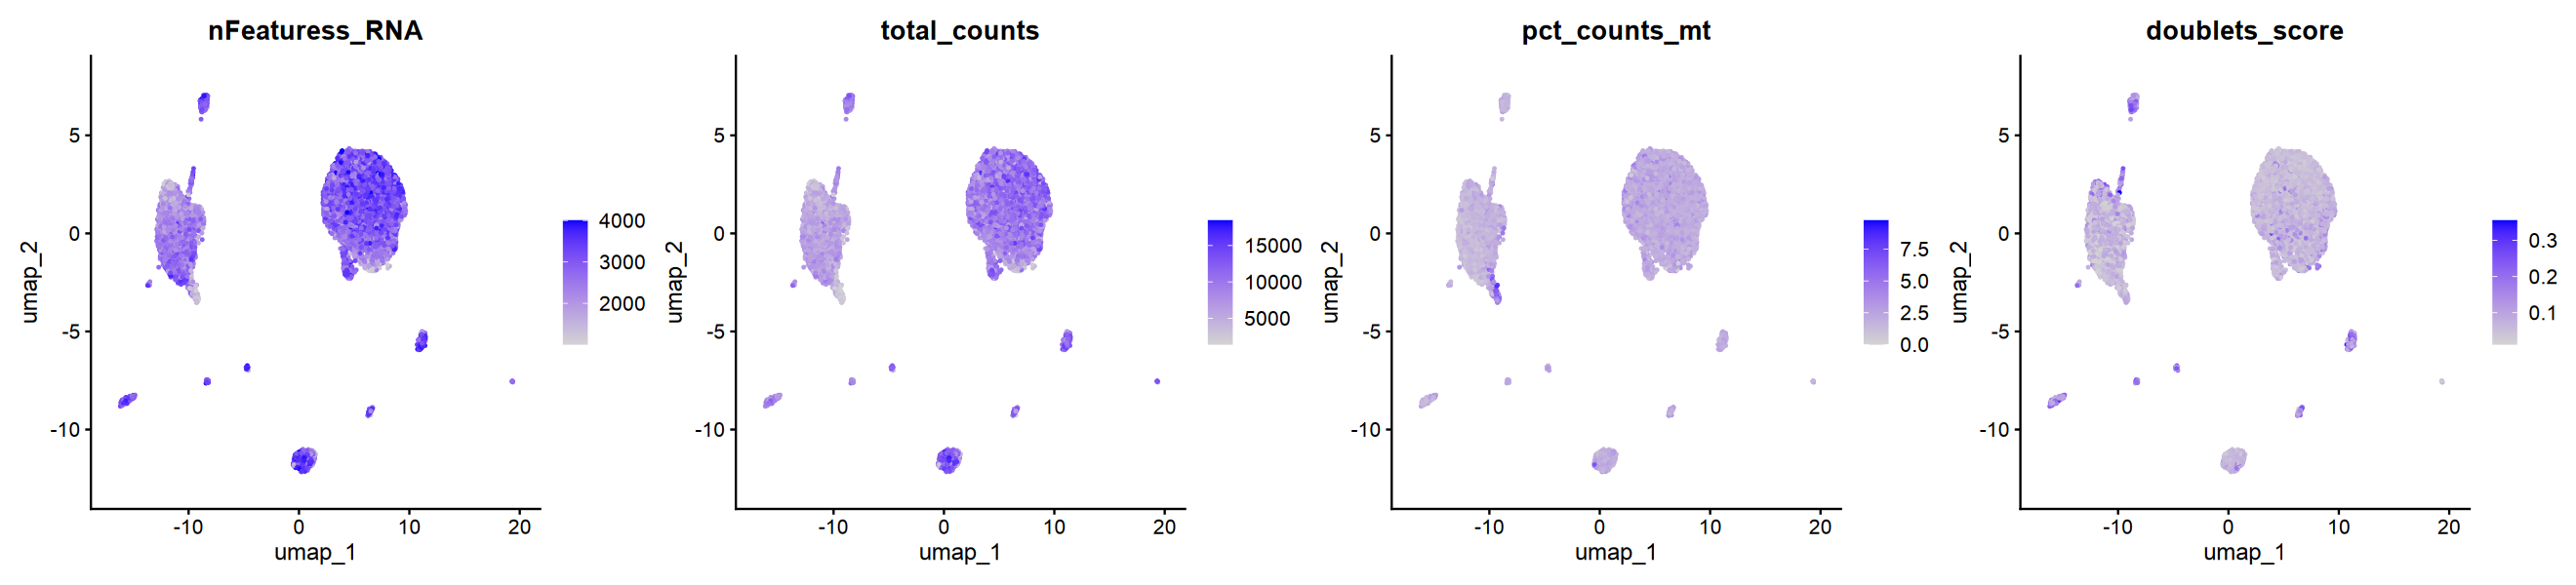

In [10]:
options(repr.plot.width=22, repr.plot.height=5)

FeaturePlot(obj, 
            features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
            reduction = 'umap', ncol=4)

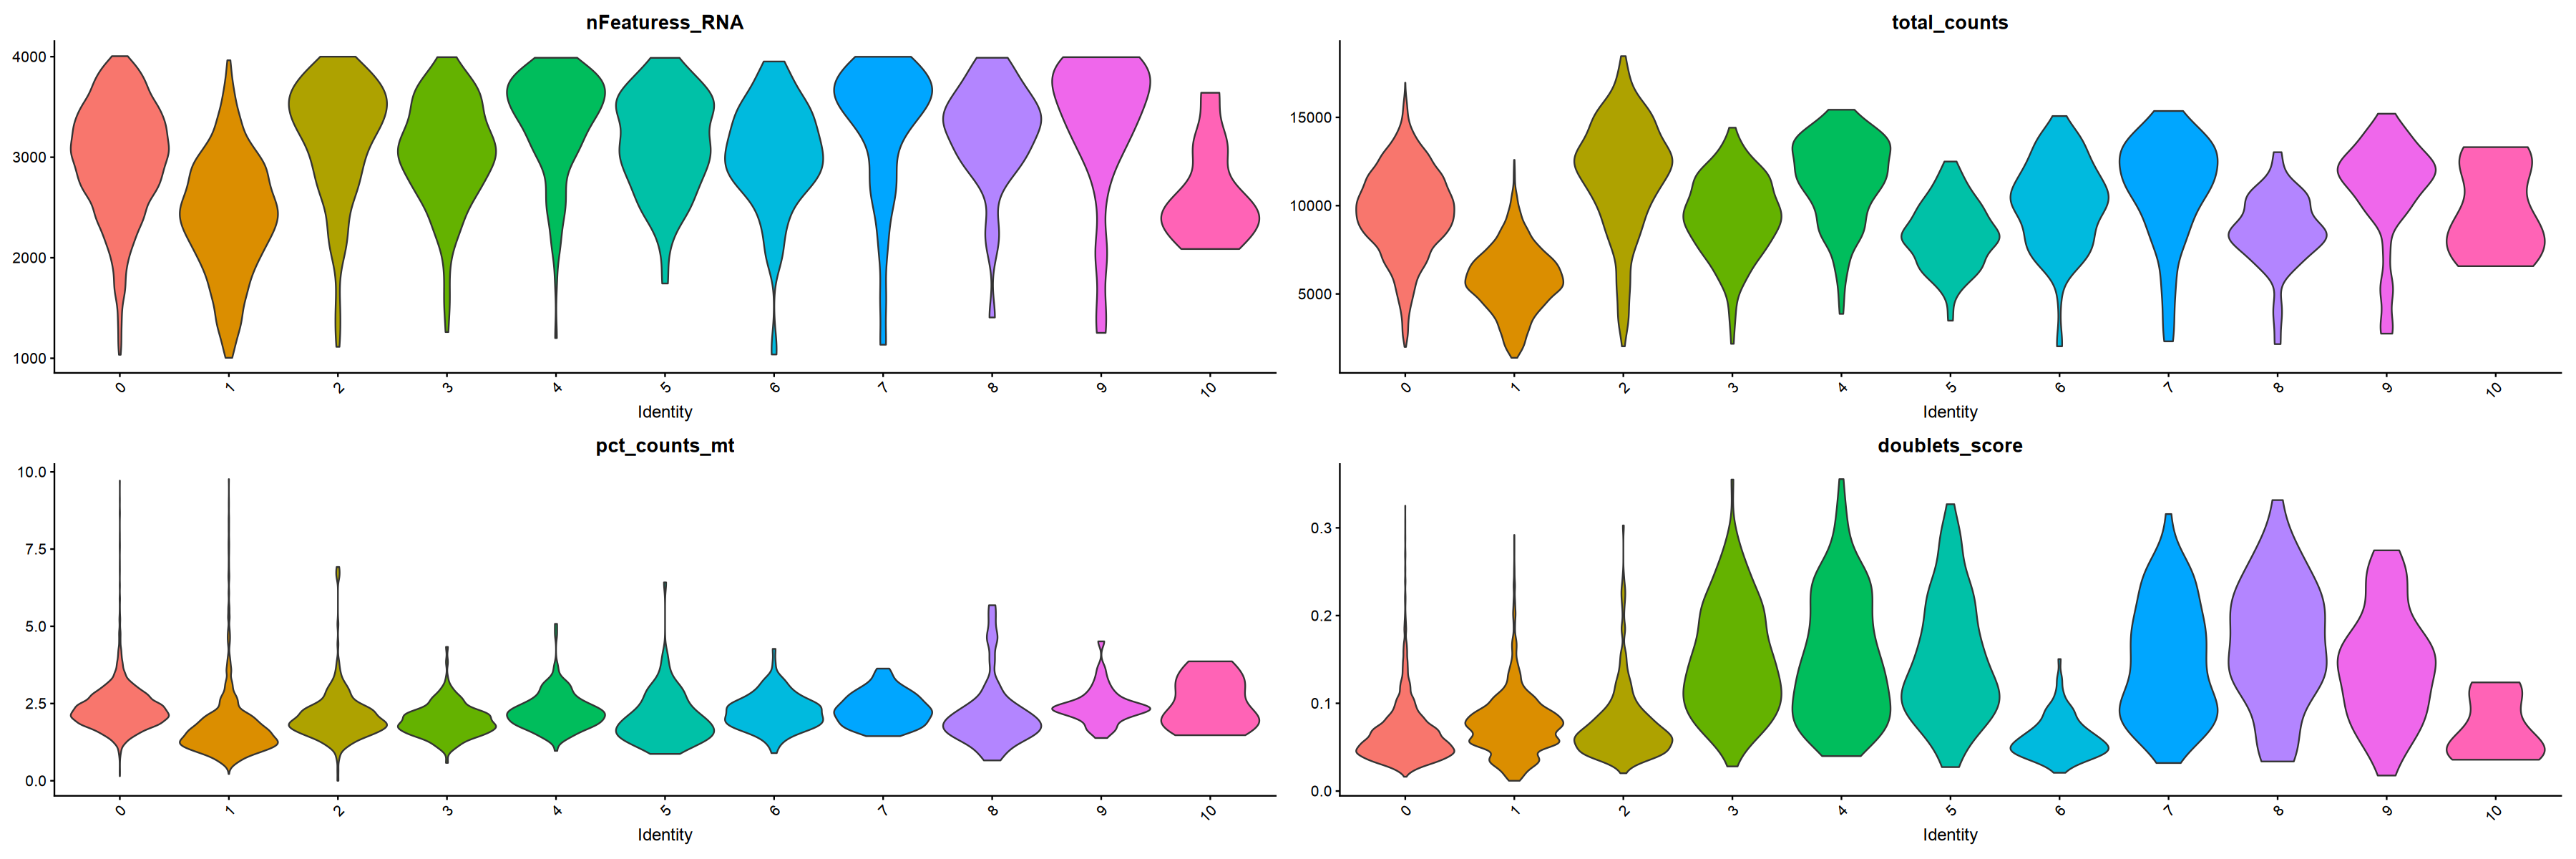

In [13]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(obj, 
        features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

In [22]:
# cluster 4 and 10 are likely doublets
# we filter them and redo clustering

ft = subset(x = obj, 
            subset = !(seurat_clusters %in% c(3,4,5, 7,8,9,10)))

ft

An object of class Seurat 
28202 features across 8012 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

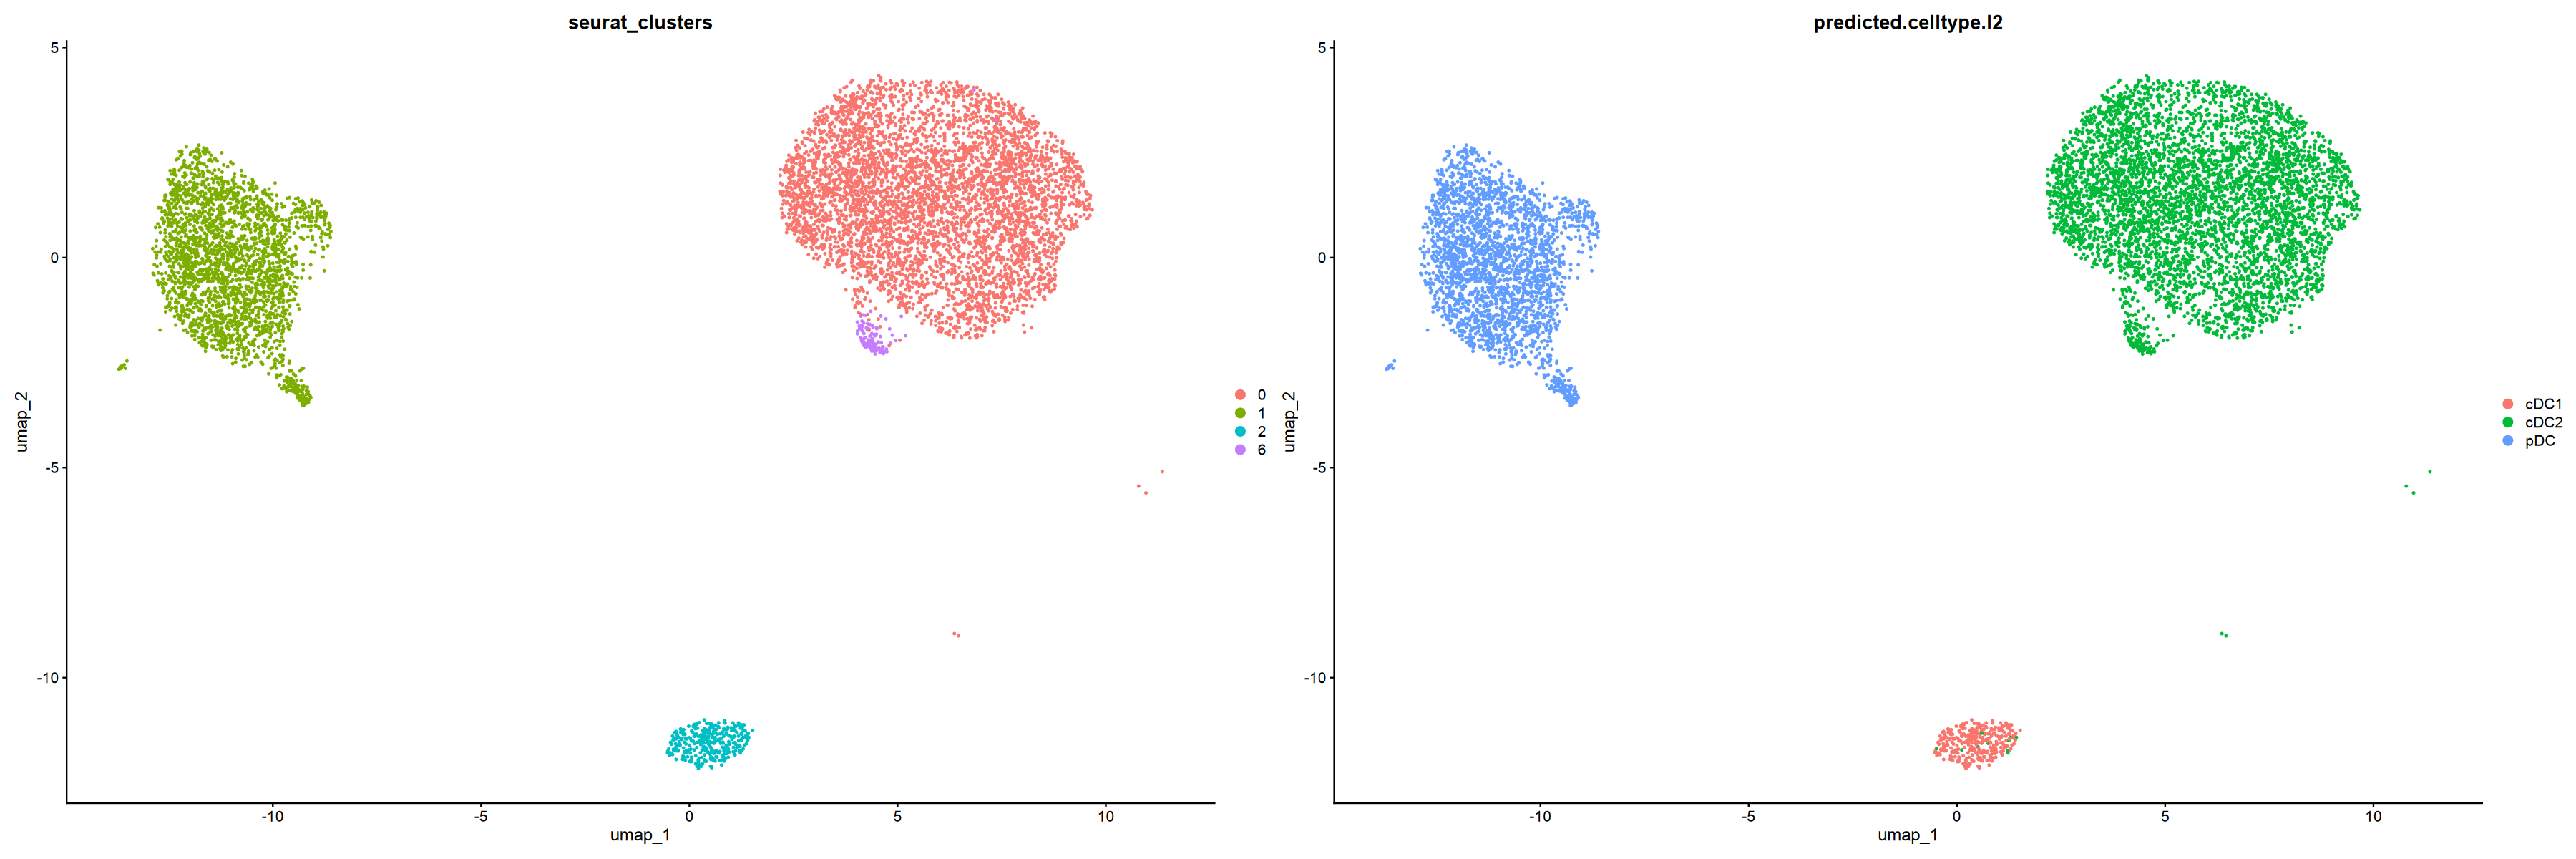

In [23]:
DimPlot(ft, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

In [24]:
ft <- FindNeighbors(ft, dims = 1:30, reduction = "harmony")
ft <- RunUMAP(ft, dims = 1:30, reduction = "harmony")

Computing nearest neighbor graph

Computing SNN

14:44:42 UMAP embedding parameters a = 0.9922 b = 1.112

14:44:42 Read 8012 rows and found 30 numeric columns

14:44:42 Using Annoy for neighbor search, n_neighbors = 30

14:44:42 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:44:44 Writing NN index file to temp file /tmp/Rtmpb57m4y/file5cb564c5592bc

14:44:44 Searching Annoy index using 1 thread, search_k = 3000

14:44:46 Annoy recall = 100%

14:44:47 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:44:48 Found 2 connected components, 
falling back to 'spca' initialization with init_sdev = 1

14:44:48 Using 'irlba' for PCA

14:44:48 PCA: 2 components explained 72.51% variance

14:44:48 Scaling init to sdev = 1

14:44:48 Com

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 8012
Number of edges: 317573

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8854
Number of communities: 6
Elapsed time: 1 seconds


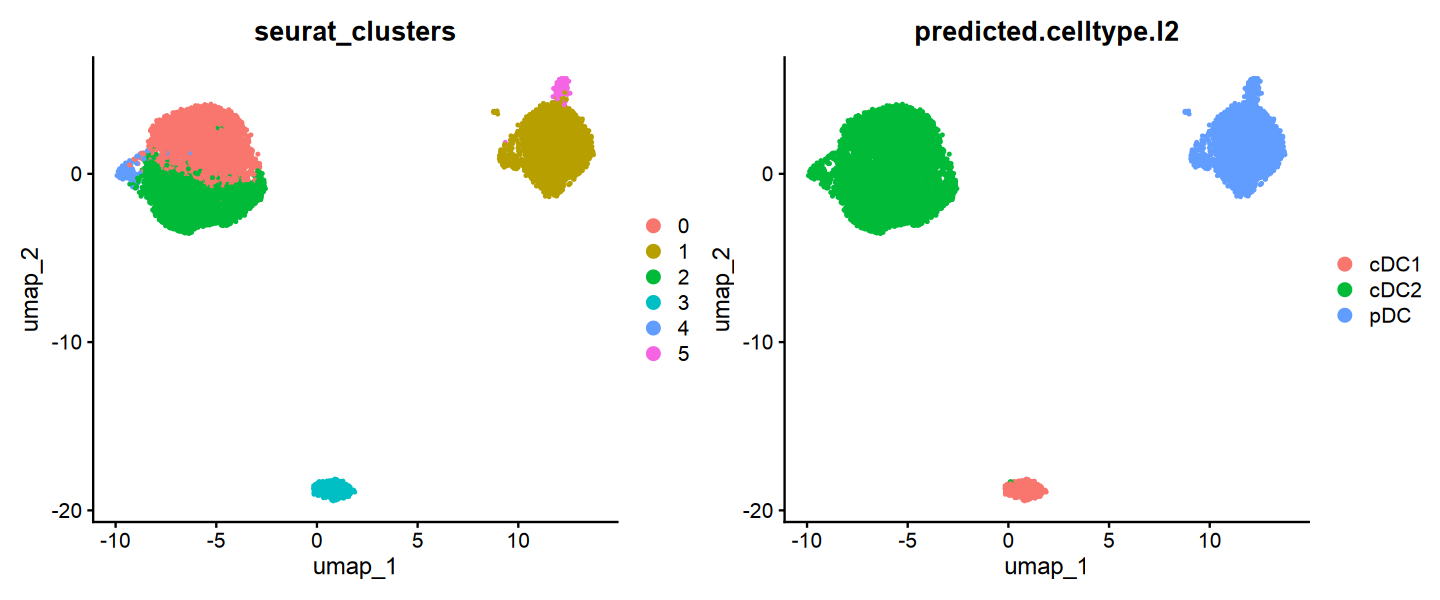

In [25]:
options(repr.plot.width=12, repr.plot.height=5)

ft <- FindClusters(ft, resolution = .3)

DimPlot(ft, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

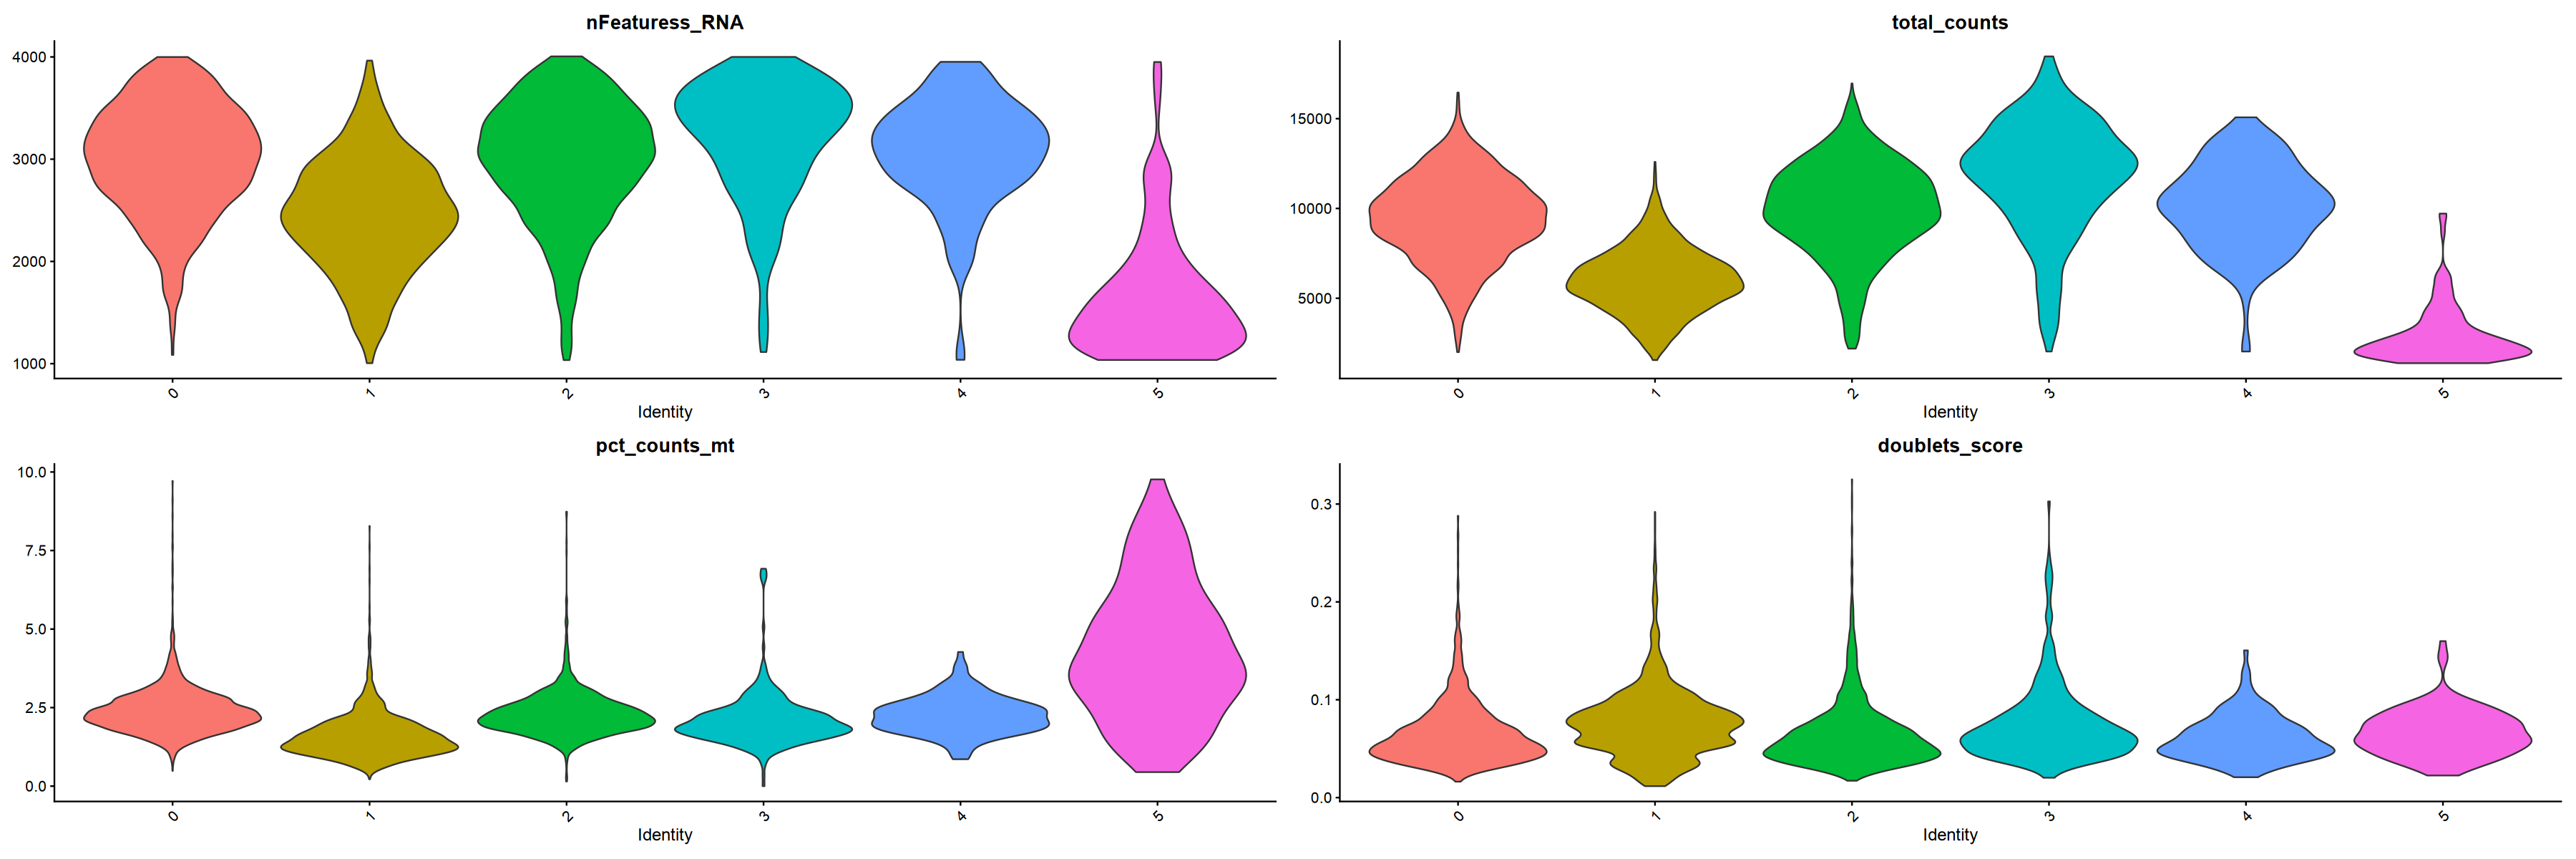

In [26]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(ft, 
        features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

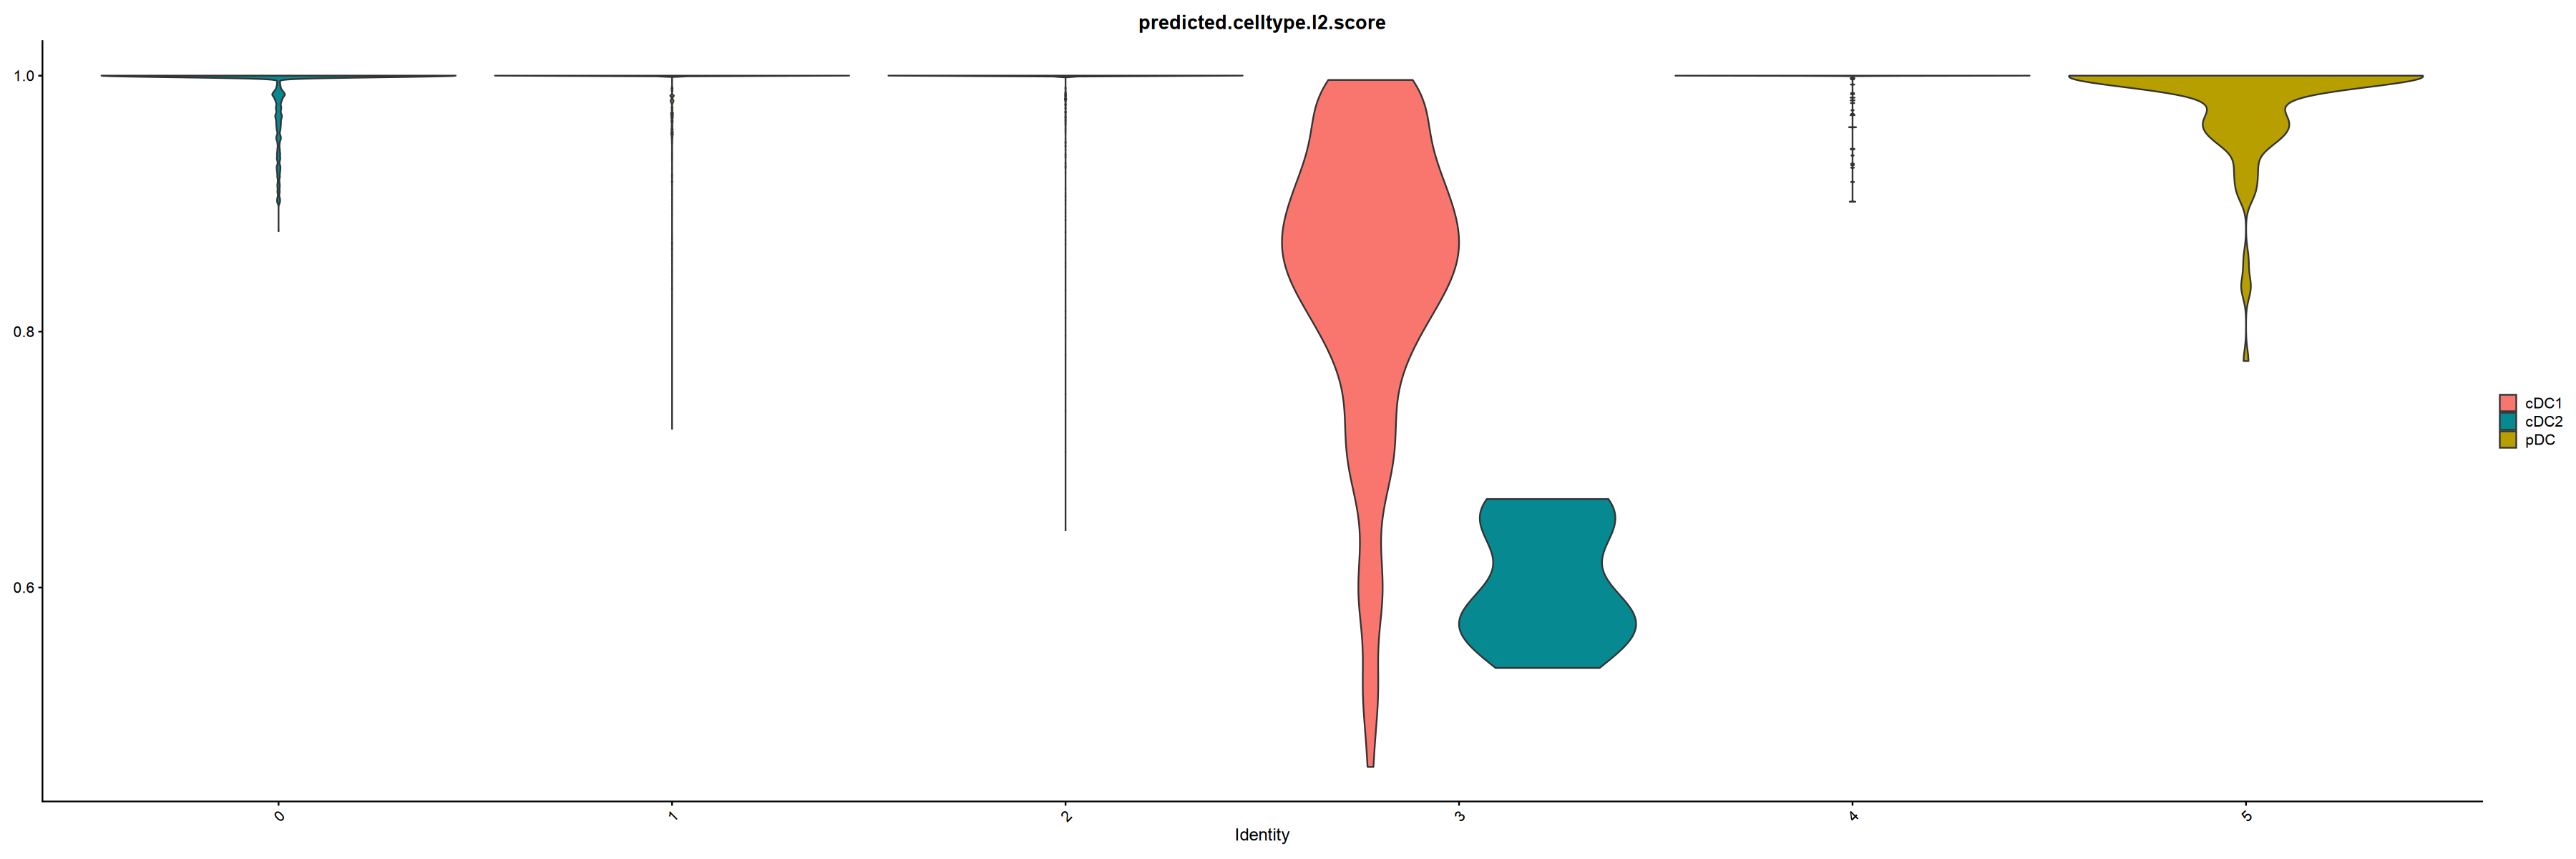

In [27]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(ft, 
        features = c('predicted.celltype.l2.score'),          
        split.by='predicted.celltype.l2', group.by='seurat_clusters', 
        ncol=1, pt.size=0)

In [28]:
ctab <- table(ft@meta.data[, c('seurat_clusters', 'predicted.celltype.l2')])
ctab_pct <- as.data.frame.matrix(prop.table(ctab, 1) * 100)

ctab_pct

,cDC1,cDC2,pDC
,<dbl>,<dbl>,<dbl>
0,0.00000,100.000000,0
1,0.00000,0.000000,100
2,0.00000,100.000000,0
3,96.51163,3.488372,0
4,0.00000,100.000000,0
5,0.00000,0.000000,100


In [29]:
max_pct <- apply(ctab_pct, 1, max)
clusters_low_purity <- as.integer(names(max_pct[max_pct < 70]) )
print(clusters_low_purity)

integer(0)


In [30]:
# for those cells which are not in clusters_low_purity, assign top predicted.celltype.l2 for that seurat_clusters
# Assume ft is your Seurat object and clusters_low_purity is already defined

# Step 1: Get cluster to top cell type mapping
ctab <- table(ft@meta.data[, c('seurat_clusters', 'predicted.celltype.l2')])
cluster_majority <- apply(ctab, 1, function(x) names(x)[which.max(x)])

# Step 2: For cells NOT in clusters_low_purity, assign top celltype
valid_clusters <- setdiff(as.integer(rownames(ctab)), clusters_low_purity)

meta_tmp <- ft@meta.data[,'seurat_clusters', drop=F]
meta_tmp$celltype_level3 <- NA  # initialize

mask <- meta_tmp$seurat_clusters %in% valid_clusters
meta_tmp$celltype_level3[mask] <- cluster_majority[as.character(meta_tmp$seurat_clusters[mask])]

anno1 = meta_tmp %>% drop_na()
dim(anno1)                       
head(anno1  )   

[1] 8012    2

,seurat_clusters,celltype_level3
,<fct>,<chr>
Pool137_10_AAACCTGGTTGGTGGA-1,2,cDC2
Pool137_10_AAAGTAGCAGGGATTG-1,4,cDC2
Pool137_10_AACCATGAGTGTTTGC-1,2,cDC2
Pool137_10_AACCGCGCATACCATG-1,2,cDC2
Pool137_10_AACCGCGGTAAATGTG-1,2,cDC2
Pool137_10_AACCGCGTCCGAGCCA-1,0,cDC2


In [31]:
anno = anno1

anno = anno[Cells(ft),]

dim(anno)
head(anno)

[1] 8012    2

,seurat_clusters,celltype_level3
,<fct>,<chr>
Pool137_10_AAACCTGGTTGGTGGA-1,2,cDC2
Pool137_10_AAAGTAGCAGGGATTG-1,4,cDC2
Pool137_10_AACCATGAGTGTTTGC-1,2,cDC2
Pool137_10_AACCGCGCATACCATG-1,2,cDC2
Pool137_10_AACCGCGGTAAATGTG-1,2,cDC2
Pool137_10_AACCGCGTCCGAGCCA-1,0,cDC2


In [32]:
ft = AddMetaData(ft, 
                 metadata = anno$celltype_level3, 
                 col.name = "celltype_level3")

In [33]:
table(ft@meta.data$celltype_level3)


cDC1 cDC2  pDC 
 344 5113 2555 

## Save

In [34]:
map <- c(
  "cDC1" = "cDC1",
  "cDC2" = "cDC2",
  "pDC" = "pDC"
)

# Map values
ft@meta.data[['celltype_level3']] <- map[ ft@meta.data[['celltype_level3']] ]

In [35]:
cell_ordered = c(
    "cDC1",
    "cDC2",
    "pDC"

)

ft@meta.data[['celltype_level3']] = factor(
    ft@meta.data[['celltype_level3']],
    levels = cell_ordered
)

In [36]:
qs::qsave(ft, glue('data/03_cleandata/ft_{celltype}.qs'))